# Milestone 3 - Exploratory Data Analysis
**Author:** Stephen Omengo Owuor

Reads the cleaned sales table from milestone 2 and looks at distributions, trends, seasonality and differences across stores, products and customers. Charts are saved to `figures/`.

> The data is synthetic, so patterns describe the simulated chain, not real Kenyan retail.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, GREY = "#1F5FA8", "#E07B00", "#9AA5B1"
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
def save(name): plt.tight_layout(); plt.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()

d = pd.read_csv("../data/clean/sales_clean.csv", parse_dates=["date"], low_memory=False)
tx = (d.groupby("transaction_id")
        .agg(date=("date", "first"), store=("store_name", "first"), revenue=("revenue", "sum"),
             items=("quantity", "sum"), lines=("line_id", "count"),
             customer=("customer_id", "first"), payment=("payment_method", "first"))
        .reset_index())
print(d.shape, tx.shape)

(302076, 32) (112202, 8)


## 1. Overview

In [2]:
overview = pd.Series({
    "Revenue (KES)": d.revenue.sum(),
    "Gross profit (KES)": d.gross_profit.sum(),
    "Gross margin": d.gross_profit.sum() / d.revenue.sum(),
    "Transactions": len(tx),
    "Average basket (KES)": tx.revenue.mean(),
    "Average lines per basket": tx.lines.mean(),
    "Stores / products / identified customers": f"{d.store_id.nunique()} / {d.product_id.nunique()} / {d.customer_id.nunique():,}",
})
overview

Revenue (KES)                                   78890104.25
Gross profit (KES)                              17284668.25
Gross margin                                       0.219098
Transactions                                         112202
Average basket (KES)                             703.107826
Average lines per basket                           2.692251
Stores / products / identified customers    10 / 98 / 4,891
dtype: object

## 2. Distributions

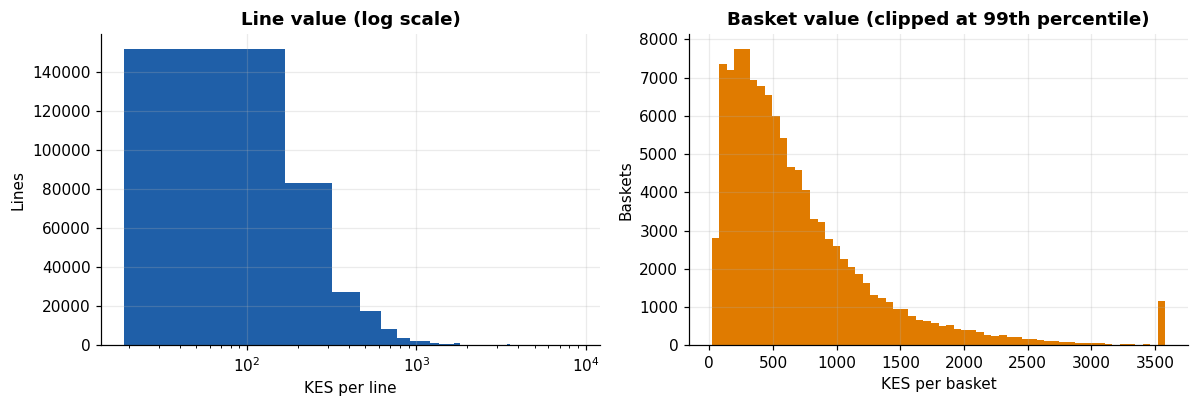

count    112202.0
mean        703.0
std         674.0
min          19.0
25%         280.0
50%         520.0
75%         905.0
max       10814.0
Name: revenue, dtype: float64
Mean / median basket: 703 / 520


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(d.revenue, bins=60, color=BLUE); ax[0].set_xscale("log")
ax[0].set_title("Line value (log scale)"); ax[0].set_xlabel("KES per line"); ax[0].set_ylabel("Lines")
ax[1].hist(tx.revenue.clip(upper=tx.revenue.quantile(0.99)), bins=60, color=ORANGE)
ax[1].set_title("Basket value (clipped at 99th percentile)"); ax[1].set_xlabel("KES per basket"); ax[1].set_ylabel("Baskets")
save("01_distributions")
print(tx.revenue.describe().round(0))
print("Mean / median basket:", round(tx.revenue.mean()), "/", round(tx.revenue.median()))

## 3. Trends and seasonality

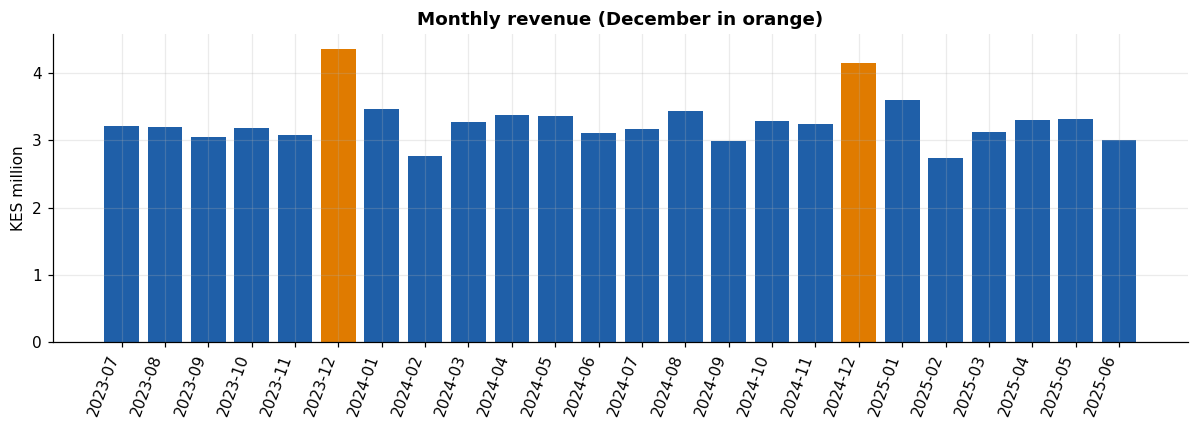

December vs average of other months: +33%
Year 2 vs year 1 revenue: -0.2%


In [4]:
monthly = d.groupby("year_month").revenue.sum()
fig, ax = plt.subplots(figsize=(11, 4))
colors = [ORANGE if m.endswith("-12") else BLUE for m in monthly.index]
ax.bar(monthly.index, monthly.values / 1e6, color=colors)
ax.set_title("Monthly revenue (December in orange)"); ax.set_ylabel("KES million")
ax.set_xticks(range(len(monthly))); ax.set_xticklabels(monthly.index, rotation=70, ha="right")
save("02_monthly_revenue")

dec = monthly[monthly.index.str.endswith("-12")].mean()
others = monthly[~monthly.index.str.endswith("-12")].mean()
print(f"December vs average of other months: {dec/others - 1:+.0%}")

h1 = monthly["2023-07":"2024-06"].sum(); h2 = monthly["2024-07":"2025-06"].sum()
print(f"Year 2 vs year 1 revenue: {h2/h1 - 1:+.1%}")

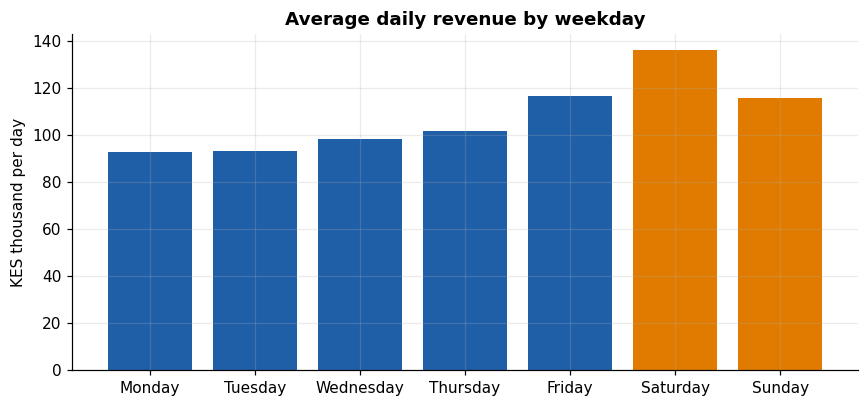

In [5]:
daily = d.groupby("date").agg(revenue=("revenue", "sum"), weekday=("day_of_week", "first"),
        weekend=("is_weekend", "first"), payday=("is_payday_window", "first"),
        holiday=("is_holiday", "first"), month=("date", lambda s: s.iloc[0].month)).reset_index()

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = daily.groupby("weekday").revenue.mean().reindex(order)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(wd.index, wd.values / 1e3, color=[ORANGE if x in ("Saturday", "Sunday") else BLUE for x in wd.index])
ax.set_title("Average daily revenue by weekday"); ax.set_ylabel("KES thousand per day")
save("03_weekday")

Weekend vs weekday:       +25%
Payday window vs other:   +28%
Public holiday vs other:  +36%
Payday window, non-December weekdays only: +29%


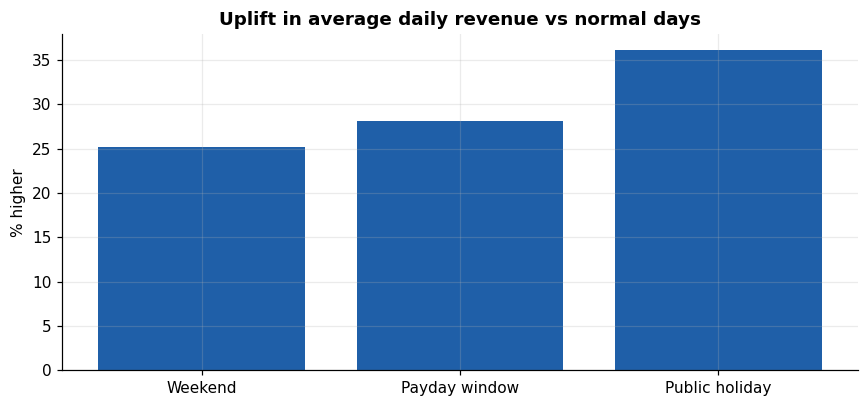

In [6]:
def effect(col):
    g = daily.groupby(col).revenue.mean()
    return g[True] / g[False] - 1

print(f"Weekend vs weekday:       {effect('weekend'):+.0%}")
print(f"Payday window vs other:   {effect('payday'):+.0%}")
print(f"Public holiday vs other:  {effect('holiday'):+.0%}")

# Overlaps (weekends, December, paydays) can inflate these, so check payday again on non-December weekdays only
base = daily[(~daily.weekend) & (daily.month != 12)]
g = base.groupby("payday").revenue.mean()
print(f"Payday window, non-December weekdays only: {g[True]/g[False] - 1:+.0%}")

fig, ax = plt.subplots(figsize=(8, 3.8))
labels = ["Weekend", "Payday window", "Public holiday"]
vals = [effect("weekend"), effect("payday"), effect("holiday")]
ax.bar(labels, [v * 100 for v in vals], color=BLUE)
ax.set_title("Uplift in average daily revenue vs normal days"); ax.set_ylabel("% higher")
save("04_calendar_effects")

## 4. Stores and counties

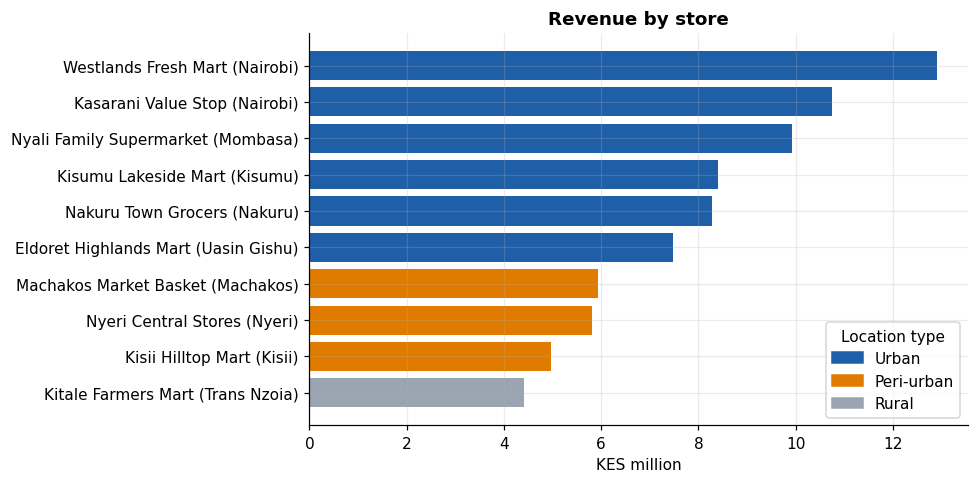

,revenue,stores,share,revenue_per_store_m
location_type,,,,
Peri-urban,16700987.00,3,0.212,5.567
Rural,4419799.75,1,0.056,4.420
Urban,57769317.50,6,0.732,9.628


In [7]:
stores = d.groupby(["store_name", "county", "location_type"]).agg(revenue=("revenue", "sum"),
          gross_profit=("gross_profit", "sum")).reset_index().sort_values("revenue")
stores["share"] = stores.revenue / stores.revenue.sum()
palette = {"Urban": BLUE, "Peri-urban": ORANGE, "Rural": GREY}
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(stores.store_name + " (" + stores.county + ")", stores.revenue / 1e6,
        color=stores.location_type.map(palette))
ax.set_title("Revenue by store"); ax.set_xlabel("KES million")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=t) for t, c in palette.items()], title="Location type", loc="lower right")
save("05_stores")

lt = d.groupby("location_type").agg(revenue=("revenue", "sum"), stores=("store_id", "nunique"))
lt["share"] = lt.revenue / lt.revenue.sum(); lt["revenue_per_store_m"] = lt.revenue / lt.stores / 1e6
lt.round(3)

In [8]:
print("Top store share:", stores.iloc[-1].store_name, f"{stores.iloc[-1].share:.1%}")
print("Margin by location type:")
print((d.groupby("location_type").gross_profit.sum() / d.groupby("location_type").revenue.sum()).round(3))

Top store share: Westlands Fresh Mart 16.3%
Margin by location type:
location_type
Peri-urban    0.219
Rural         0.219
Urban         0.219
dtype: float64


## 5. Products and categories

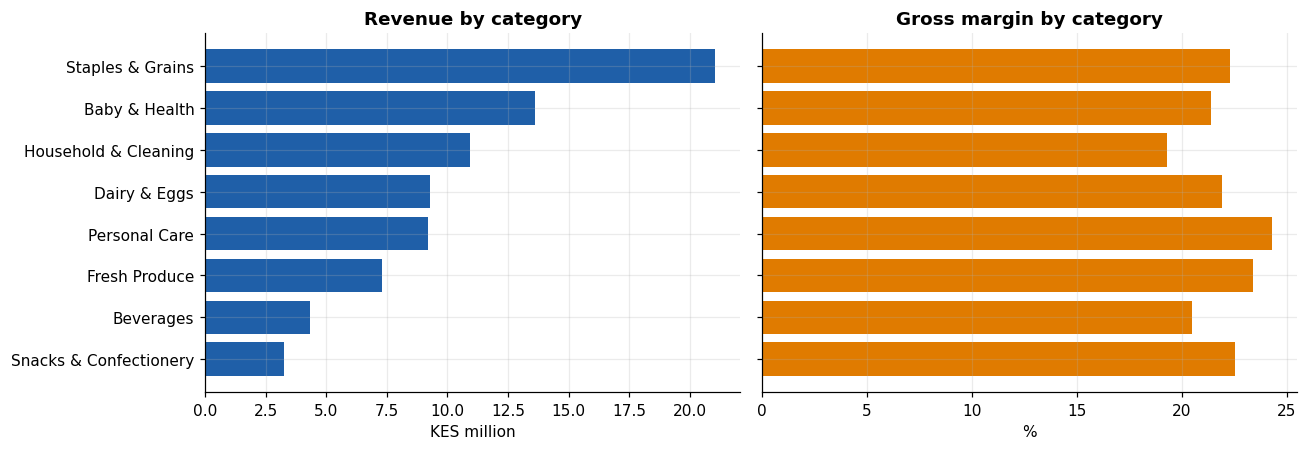

,category,revenue,gross_profit,margin,share
7,Staples & Grains,21020508.25,4681938.25,0.223,0.266
0,Baby & Health,13606124.50,2908447.50,0.214,0.172
4,Household & Cleaning,10909723.25,2102618.25,0.193,0.138
2,Dairy & Eggs,9291685.50,2034887.50,0.219,0.118
5,Personal Care,9204223.00,2235030.00,0.243,0.117
3,Fresh Produce,7292850.00,1705521.00,0.234,0.092
1,Beverages,4317984.75,885254.75,0.205,0.055
6,Snacks & Confectionery,3247005.00,730971.00,0.225,0.041


In [9]:
cat = d.groupby("category").agg(revenue=("revenue", "sum"), gross_profit=("gross_profit", "sum")).reset_index()
cat["margin"] = cat.gross_profit / cat.revenue
cat["share"] = cat.revenue / cat.revenue.sum()
cat = cat.sort_values("revenue")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
ax[0].barh(cat.category, cat.revenue / 1e6, color=BLUE); ax[0].set_title("Revenue by category"); ax[0].set_xlabel("KES million")
ax[1].barh(cat.category, cat.margin * 100, color=ORANGE); ax[1].set_title("Gross margin by category"); ax[1].set_xlabel("%")
save("06_categories")
cat.sort_values("revenue", ascending=False).round(3)

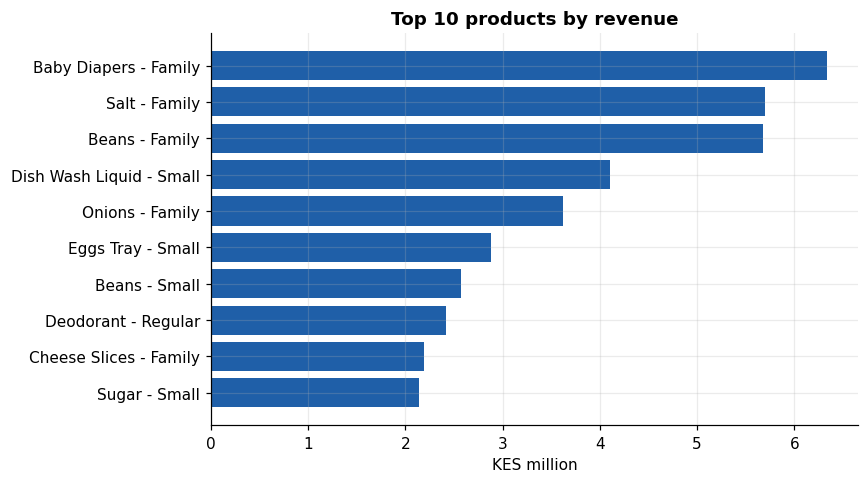

Top 10 products = 48% of revenue
Top 20% of products (19) = 65% of revenue


In [10]:
prod = d.groupby("product_name").revenue.sum().sort_values(ascending=False)
top10 = prod.head(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top10.index, top10.values / 1e6, color=BLUE)
ax.set_title("Top 10 products by revenue"); ax.set_xlabel("KES million")
save("07_top_products")
print(f"Top 10 products = {prod.head(10).sum()/prod.sum():.0%} of revenue")
print(f"Top 20% of products ({int(len(prod)*0.2)}) = {prod.head(int(len(prod)*0.2)).sum()/prod.sum():.0%} of revenue")

## 6. Customers

Revenue from identified customers: 58%; guests: 42%


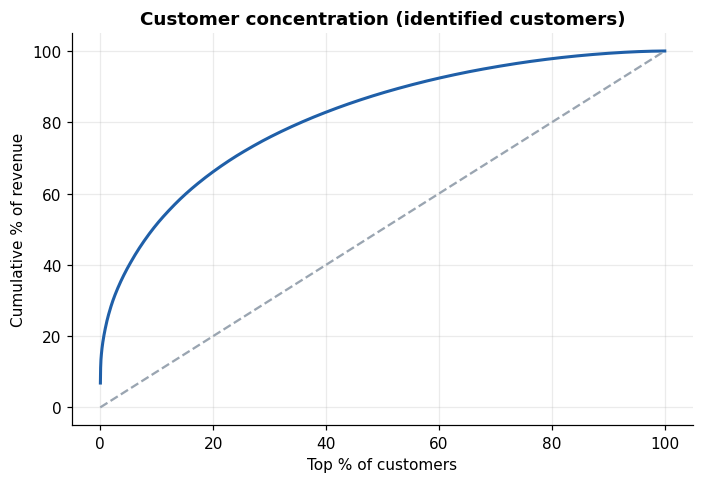

Top 10% of identified customers = 51% of identified revenue


In [11]:
known = d.dropna(subset=["customer_id"])
print(f"Revenue from identified customers: {known.revenue.sum()/d.revenue.sum():.0%}; guests: {1 - known.revenue.sum()/d.revenue.sum():.0%}")

cust = known.groupby("customer_id").revenue.sum().sort_values(ascending=False)
cum = cust.cumsum() / cust.sum()
x = np.arange(1, len(cum) + 1) / len(cum)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(x * 100, cum.values * 100, color=BLUE, lw=2); ax.plot([0, 100], [0, 100], color=GREY, ls="--")
ax.set_title("Customer concentration (identified customers)")
ax.set_xlabel("Top % of customers"); ax.set_ylabel("Cumulative % of revenue")
save("08_customer_concentration")
print(f"Top 10% of identified customers = {cum.iloc[int(len(cum)*0.1)-1]:.0%} of identified revenue")

Average basket - guest vs identified: {False: 702.0, True: 704.0}


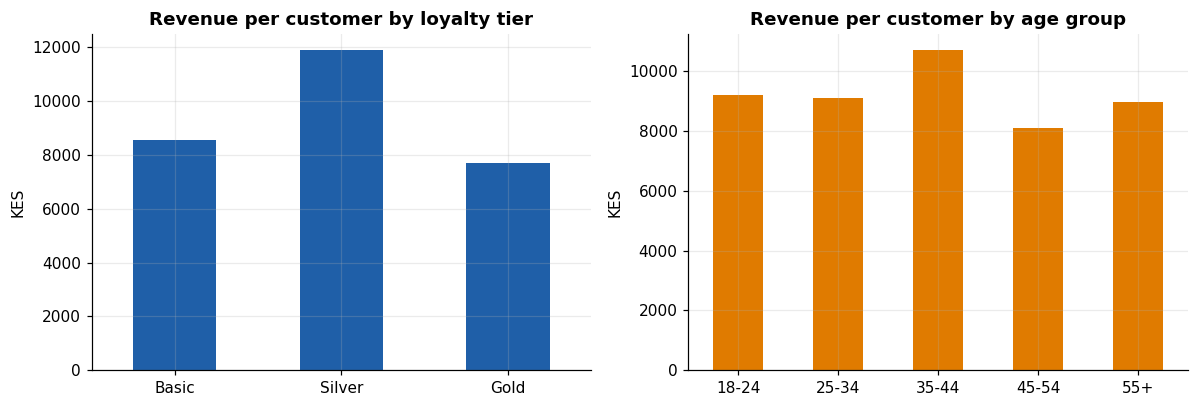

,customers,revenue,revenue_per_customer
loyalty_tier,,,
Basic,3043,25995014.0,8543.0
Gold,502,3860064.0,7689.0
Silver,1346,16003513.0,11890.0


In [12]:
tier = tx.assign(member=tx.customer.notna()).groupby("member").revenue.mean()
print("Average basket - guest vs identified:", tier.round(0).to_dict())

seg = known.groupby("loyalty_tier").agg(customers=("customer_id", "nunique"), revenue=("revenue", "sum"))
seg["revenue_per_customer"] = seg.revenue / seg.customers
age = known.groupby("age_group").agg(customers=("customer_id", "nunique"), revenue=("revenue", "sum"))
age["revenue_per_customer"] = age.revenue / age.customers

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
seg.reindex(["Basic", "Silver", "Gold"]).revenue_per_customer.plot.bar(ax=ax[0], color=BLUE, rot=0)
ax[0].set_title("Revenue per customer by loyalty tier"); ax[0].set_ylabel("KES"); ax[0].set_xlabel("")
age.revenue_per_customer.plot.bar(ax=ax[1], color=ORANGE, rot=0)
ax[1].set_title("Revenue per customer by age group"); ax[1].set_ylabel("KES"); ax[1].set_xlabel("")
save("09_customer_segments")
pd.concat([seg.round(0), ], axis=1)

## 7. Payments and promotions

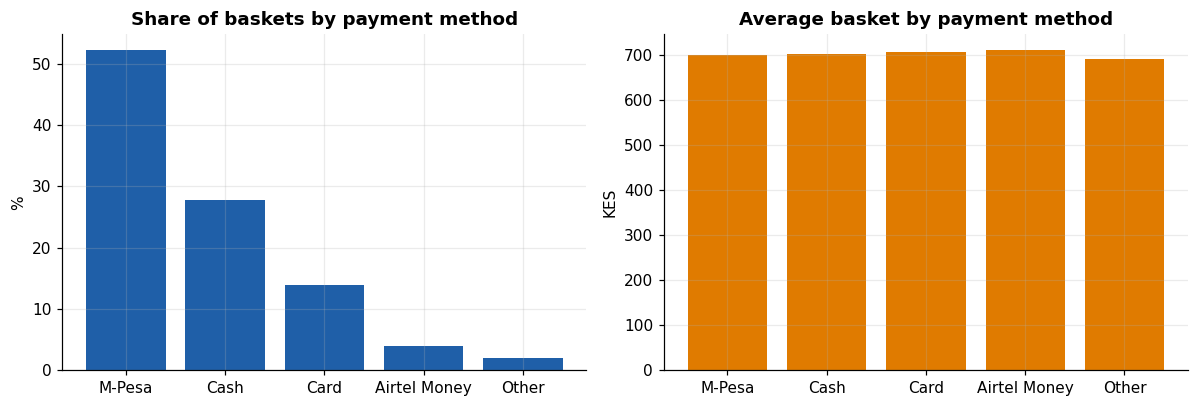

,baskets,avg_basket,share
payment,,,
M-Pesa,58568,701.681,0.522
Cash,31219,704.184,0.278
Card,15558,707.579,0.139
Airtel Money,4533,711.654,0.040
Other,2237,691.942,0.020


In [13]:
pay = tx[tx.payment != "Unknown"].groupby("payment").agg(baskets=("transaction_id", "count"), avg_basket=("revenue", "mean"))
pay["share"] = pay.baskets / pay.baskets.sum()
pay = pay.sort_values("baskets", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(pay.index, pay.share * 100, color=BLUE); ax[0].set_title("Share of baskets by payment method"); ax[0].set_ylabel("%")
ax[1].bar(pay.index, pay.avg_basket, color=ORANGE); ax[1].set_title("Average basket by payment method"); ax[1].set_ylabel("KES")
save("10_payments")
pay.round(3)

In [14]:
promo = d.groupby("has_promo").agg(lines=("line_id", "count"), avg_qty=("quantity", "mean"), avg_discount=("discount_pct", "mean"))
promo.index = ["No promotion", "On promotion"]
print(promo.round(3))
print(f"Share of lines sold on promotion: {d.has_promo.mean():.1%}")
print(f"Discount cost: KES {(d.quantity * d.unit_price - d.revenue).sum():,.0f} ({(d.quantity * d.unit_price - d.revenue).sum() / (d.quantity * d.unit_price).sum():.1%} of list-price sales)")

               lines  avg_qty  avg_discount
No promotion  283900    1.599         0.000
On promotion   18176    1.606        14.638
Share of lines sold on promotion: 6.0%
Discount cost: KES 645,121 (0.8% of list-price sales)


## Five findings that matter most
Write your own conclusion for each one here after reading the outputs above (what you see, the number, and what a manager should do about it):

1. Seasonality and calendar:
2. Store concentration:
3. Product concentration and margin:
4. Customer concentration:
5. Payments and promotions: